In [29]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import numpy as np
import pandas as pd

train_dir = '/content/drive/MyDrive/ImagesML/training/'
test_dir = '/content/drive/MyDrive/ImagesML/test/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = dir.name

        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if img is not None:
                img_list.append((img, label))

    return img_list

train_img = load_dataset(train_dir)

print(f'Total training images: {len(train_img)}')

Total training images: 240


In [31]:
pick_random = np.random.randint(0, len(train_img))

print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)
print(train_img[pick_random][1])

Image 229
(700, 1280, 3)
night


Shape	: (469, 640, 3)
Label	: day


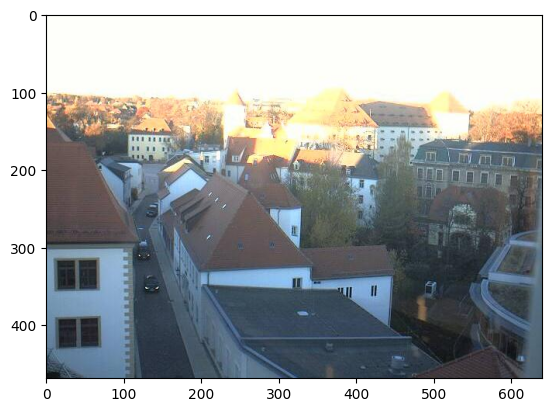

In [32]:
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.imshow(img)

    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

random_img_viz(train_img)
plt.show()

In [33]:
def standarized_input(image):
    std_img = cv2.resize(image, (1100, 600))

    return std_img

def label_encoder(label):
    num_val = 0

    if label == 'day':
        num_val = 1

    return num_val

def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        std_img = standarized_input(image)

        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

train_std_img_list = preprocess(train_img)

In [34]:
pick_random = np.random.randint(0, len(train_std_img_list))

print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 86
(600, 1100, 3)


Image 206
Avg Brightness: 99.6236


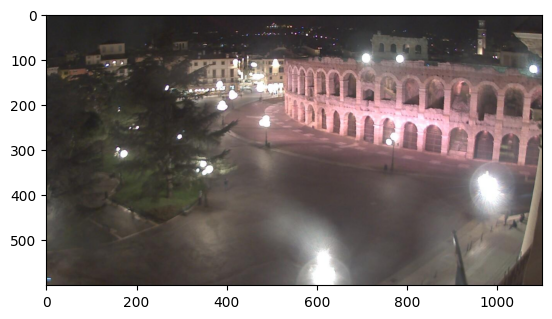

In [35]:
def avg_brightness(image):
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    sum_brightness = np.sum(img_hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brightness: {avg_img:.4f}')

plt.imshow(feature_img)
plt.show()

In [36]:
def predict_label(img, threshold):
    avg = avg_brightness(img)
    pred = 0

    if avg > threshold:
        pred = 1

    return pred

rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')

Image 50
Actual label: 1
Predicted label: 1


In [37]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        img = file[0]
        label = file[1]

        pred_label = predict_label(img, threshold)

        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [38]:
test_img = load_dataset(test_dir)

test_std_img_list = preprocess(test_img)

evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


In [39]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]

        avg_list.append(img_avg)
        labels.append(img_label)

    data = np.column_stack((avg_list, labels))

    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

train_avg_img = extract_avg_bright_feature(train_std_img_list)

print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,175.092992,1.0
1,109.039258,1.0
2,197.451662,1.0
3,187.700786,1.0
4,195.107926,1.0


In [40]:
test_avg_img = extract_avg_bright_feature(test_std_img_list)

print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,184.670024,1.0
1,191.237441,1.0
2,188.119652,1.0
3,161.989627,1.0
4,185.917073,1.0


In [41]:
from sklearn.svm import SVC

X_train = train_avg_img[['AVG_BRIGHT']].values
y_train = train_avg_img['LABELS'].astype(int)
X_test = test_avg_img[['AVG_BRIGHT']].values
y_test = test_avg_img['LABELS'].astype(int)

print(X_train.shape, X_test.shape)

model = SVC()
model.fit(X_train, y_train)

(240, 1) (160, 1)


SVC()

In [42]:
print(train_avg_img['LABELS'].value_counts())
print(test_avg_img['LABELS'].value_counts())

for d in [train_dir, test_dir]:
    p = Path(d)
    print(d)
    for sub in p.glob('*'):
        print('  ', sub.name, '->', len(list(sub.glob('*.jpg'))), 'jpg files')


LABELS
1.0    120
0.0    120
Name: count, dtype: int64
LABELS
1.0    80
0.0    80
Name: count, dtype: int64
/content/drive/MyDrive/ImagesML/training/
   day -> 120 jpg files
   night -> 120 jpg files
/content/drive/MyDrive/ImagesML/test/
   day -> 80 jpg files
   night -> 80 jpg files


In [43]:
from sklearn.metrics import accuracy_score

y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9
